# 03 - Exploratory Data Analysis

## Objective

The objective of this notebook is to analyse the
cleaned DataCo Supply Chain dataset and identify
patterns in delivery performance, shipping modes,
regional performance, sales and profitability.

We will use Python, Pandas, NumPy, Matplotlib
and Seaborn to perform the analysis.

In [2]:
# Importing libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# configuring the chart, visualization appearance

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)

In [4]:
# Loading the Data 
df = pd.read_csv(
    "../data/processed/supply_chain_cleaned.csv",
    parse_dates=[
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (180519, 40)


,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,...,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,shipping date (DateOrders),Shipping Mode,shipping_delay_days
0,DEBIT,3,4,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,...,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,2018-02-03 22:56:00,Standard Class,-1
1,TRANSFER,5,4,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,...,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,2018-01-18 12:27:00,Standard Class,1
2,CASH,4,4,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,19491,Consumer,...,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,2018-01-17 12:06:00,Standard Class,0
3,DEBIT,3,4,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,...,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,2018-01-16 11:45:00,Standard Class,-1
4,PAYMENT,2,4,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,...,Oceania,Queensland,PENDING_PAYMENT,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,2018-01-15 11:24:00,Standard Class,-2


# 3.1 Dataset Verification

We verify the dimensions, column names,
data types and date range of the cleaned dataset
before beginning the analysis.

In [5]:
print("Rows and columns:", df.shape)

print("\nTotal columns:", len(df.columns))

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes.to_string())

Rows and columns: (180519, 40)

Total columns: 40

Missing values: 0

Duplicate rows: 0

Data types:
Type                                        str
Days for shipping (real)                  int64
Days for shipment (scheduled)             int64
Delivery Status                             str
Late_delivery_risk                        int64
Category Name                               str
Customer City                               str
Customer Country                            str
Customer Id                               int64
Customer Segment                            str
Customer State                              str
Department Id                             int64
Department Name                             str
Latitude                                float64
Longitude                               float64
Market                                      str
Order City                                  str
Order Country                               str
Order Customer Id                  

In [6]:
# Order date range checking 

print(
    "First order date:",
    df["order date (DateOrders)"].min()
)

print(
    "Last order date:",
    df["order date (DateOrders)"].max()
)

First order date: 2015-01-01 00:00:00
Last order date: 2018-01-31 23:38:00


# 3.2 Overall Business KPIs

We calculate basic business metrics to understand
the overall scale of the dataset.

These include total order items, unique orders,
unique customers, sales values and delivery status.

In [7]:
total_records = len(df)

total_orders = df["Order Id"].nunique()

total_order_items = df["Order Item Id"].nunique()

total_customers = df["Customer Id"].nunique()

total_sales = df["Sales"].sum()

total_order_item_value = df["Order Item Total"].sum()

average_order_item_value = df["Order Item Total"].mean()


print("Total Records:", total_records)

print("Total Unique Orders:", total_orders)

print("Total Order Items:", total_order_items)

print("Total Unique Customers:", total_customers)

print("Total Sales:", round(total_sales, 2))

print("Total Order Item Value:", round(total_order_item_value, 2))

print("Average Order Item Value:", round(average_order_item_value, 2))

Total Records: 180519
Total Unique Orders: 65752
Total Order Items: 180519
Total Unique Customers: 20652
Total Sales: 36784735.01
Total Order Item Value: 33054402.38
Average Order Item Value: 183.11


# 3.3 Overall Delivery Performance

We analyse delivery status to understand the
proportion of late, on-time, advance and cancelled
shipment records.

We also calculate the late-delivery percentage
excluding cancelled shipments.

In [8]:
delivery_counts = df["Delivery Status"].value_counts()

print("Delivery Status Counts:")
print(delivery_counts)

Delivery Status Counts:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64


In [9]:
# calculating delivery percentage

delivery_percentages = (
    df["Delivery Status"]
    .value_counts(normalize=True)
    * 100
)

print("Delivery Status Percentages:")
print(delivery_percentages.round(2))

Delivery Status Percentages:
Delivery Status
Late delivery        54.83
Advance shipping     23.04
Shipping on time     17.84
Shipping canceled     4.30
Name: proportion, dtype: float64


In [10]:
# particular late delivery percentage calculation

total_delivery_records = len(df)

cancelled_records = (
    df["Delivery Status"] == "Shipping canceled"
).sum()

non_cancelled_records = (
    total_delivery_records - cancelled_records
)

late_delivery_records = (
    df["Delivery Status"] == "Late delivery"
).sum()

late_delivery_percentage = (
    late_delivery_records / non_cancelled_records
) * 100

print("Total Records:", total_delivery_records)

print("Cancelled Records:", cancelled_records)

print("Non-cancelled Records:", non_cancelled_records)

print("Late Delivery Records:", late_delivery_records)

print(
    "Late Delivery Percentage:",
    round(late_delivery_percentage, 2),
    "%"
)

Total Records: 180519
Cancelled Records: 7754
Non-cancelled Records: 172765
Late Delivery Records: 98977
Late Delivery Percentage: 57.29 %


In [11]:
# order cancellation percentage 

cancellation_percentage = (
    cancelled_records / total_delivery_records
) * 100

print(
    "Cancellation Percentage:",
    round(cancellation_percentage, 2),
    "%"
)

Cancellation Percentage: 4.3 %


In [12]:
# creating a KPI TABLE based on the available information
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Orders",
        "Unique Order Items",
        "Unique Customers",
        "Total Sales",
        "Total Order Item Value",
        "Average Order Item Value",
        "Late Delivery Records",
        "Late Delivery Percentage",
        "Cancelled Delivery Records",
        "Cancellation Percentage"
    ],

    "Value": [
        total_records,
        total_orders,
        total_order_items,
        total_customers,
        round(total_sales, 2),
        round(total_order_item_value, 2),
        round(average_order_item_value, 2),
        late_delivery_records,
        round(late_delivery_percentage, 2),
        cancelled_records,
        round(cancellation_percentage, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Records,180519.00
1,Unique Orders,65752.00
2,Unique Order Items,180519.00
3,Unique Customers,20652.00
4,Total Sales,36784735.01
5,Total Order Item Value,33054402.38
6,Average Order Item Value,183.11
7,Late Delivery Records,98977.00
8,Late Delivery Percentage,57.29
9,Cancelled Delivery Records,7754.00


# 3.4. Delivery Status Distribution

We visualise the number of order-item records
belonging to each delivery-status category.

This helps us understand the overall distribution
of delivery performance.

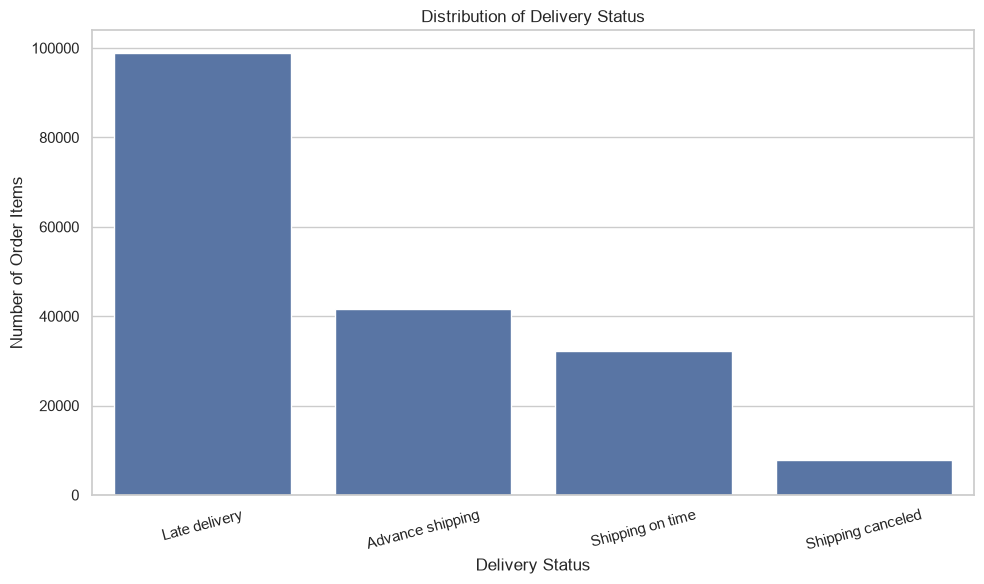

In [13]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Delivery Status",
    order=df["Delivery Status"].value_counts().index
)

plt.title("Distribution of Delivery Status")

plt.xlabel("Delivery Status")

plt.ylabel("Number of Order Items")

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

# 3.5 Shipping Mode Analysis

We analyse delivery performance across different
shipping modes to identify which modes have
higher late-delivery rates

In [14]:
shipping_mode_counts = df["Shipping Mode"].value_counts()

print(shipping_mode_counts)

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64


In [15]:
# comparing delivery status over delivery modes

shipping_delivery_table = pd.crosstab(
    df["Shipping Mode"],
    df["Delivery Status"]
)

display(shipping_delivery_table)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0,26513,1301,0
Same Day,0,4454,444,4839
Second Class,0,26987,1410,6819
Standard Class,41592,41023,4599,20538


In [16]:
# Calculate the late-delivery rate for each shipping mode
non_cancelled_df = df[
    df["Delivery Status"] != "Shipping canceled"
].copy()

print("Original records:", len(df))

print("Non-cancelled records:", len(non_cancelled_df))

Original records: 180519
Non-cancelled records: 172765


In [17]:
# Performance of each shipping mode

shipping_analysis = (
    non_cancelled_df
    .groupby("Shipping Mode")
    .agg(
        total_records=("Order Id", "size"),

        late_records=(
            "Delivery Status",
            lambda x: (x == "Late delivery").sum()
        ),

        average_actual_days=(
            "Days for shipping (real)",
            "mean"
        ),

        average_scheduled_days=(
            "Days for shipment (scheduled)",
            "mean"
        )
    )
)

shipping_analysis["late_delivery_rate"] = (
    shipping_analysis["late_records"]
    / shipping_analysis["total_records"]
) * 100

shipping_analysis = shipping_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

display(shipping_analysis.round(2))

,total_records,late_records,average_actual_days,average_scheduled_days,late_delivery_rate
Shipping Mode,,,,,
First Class,26513,26513,2.00,1.0,100.00
Second Class,33806,26987,3.99,2.0,79.83
Same Day,9293,4454,0.48,0.0,47.93
Standard Class,103153,41023,3.99,4.0,39.77


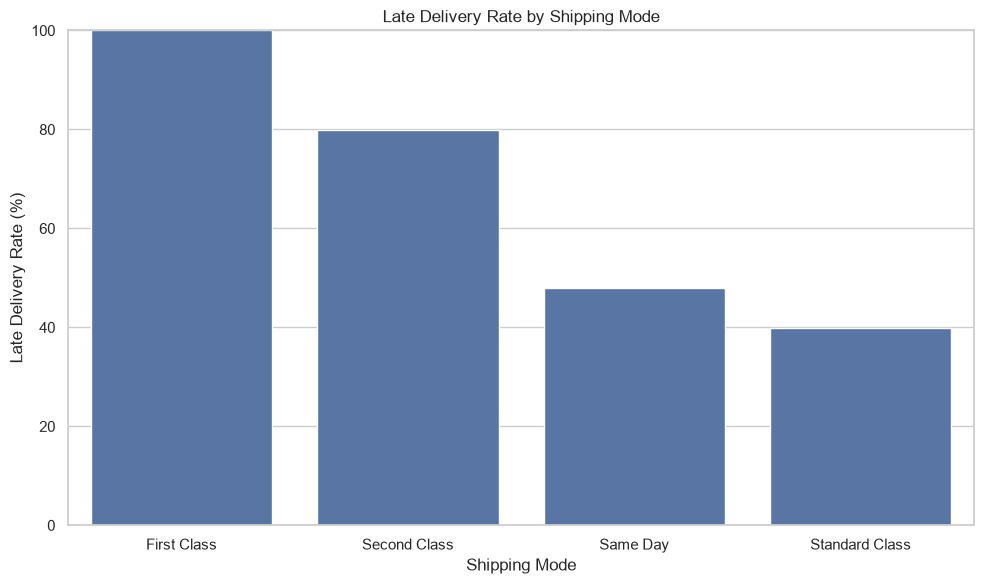

In [18]:
# Visualise late-delivery rates by shipping mode

plt.figure(figsize=(10, 6))

sns.barplot(
    data=shipping_analysis.reset_index(),
    x="Shipping Mode",
    y="late_delivery_rate"
)

plt.title("Late Delivery Rate by Shipping Mode")

plt.xlabel("Shipping Mode")

plt.ylabel("Late Delivery Rate (%)")

plt.ylim(0, 100)

plt.tight_layout()

plt.show()

In [19]:
# Investigate cancellation rates separately

cancellation_analysis = (
    df.assign(
        is_cancelled=(
            df["Delivery Status"] == "Shipping canceled"
        )
    )
    .groupby("Shipping Mode")
    .agg(
        total_records=("Order Id", "size"),
        cancelled_records=("is_cancelled", "sum")
    )
)

cancellation_analysis["cancellation_rate"] = (
    cancellation_analysis["cancelled_records"]
    / cancellation_analysis["total_records"]
) * 100

display(cancellation_analysis.round(2))

,total_records,cancelled_records,cancellation_rate
Shipping Mode,,,
First Class,27814,1301,4.68
Same Day,9737,444,4.56
Second Class,35216,1410,4.00
Standard Class,107752,4599,4.27


## Business Findings: Shipping Mode Analysis

1. The most frequently used shipping mode is STANDARD CLASS.

2. The shipping mode with the highest late-delivery
   rate is FIRST CLASS.

3. The shipping mode with the lowest late-delivery
   rate is STANDARD CLASS.

4. The shipping mode with the highest cancellation
   rate is First Class.

5. The results suggest that delivery performance
   varies across shipping modes.

6. Further investigation is required to understand
   whether geographical location, order volume,
   product category or other factors contribute
   to these differences.

# 3.6 Regional Delivery Performance Analysis

We investigate delivery performance across different
geographical regions to identify areas with higher
late-delivery rates.

In [20]:
print("Number of unique regions:", df["Order Region"].nunique())

print("\nAvailable regions:")

print(df["Order Region"].value_counts())

Number of unique regions: 23

Available regions:
Order Region
Central America    28341
Western Europe     27109
South America      14935
Oceania            10148
Northern Europe     9792
Southeast Asia      9539
Southern Europe     9431
Caribbean           8318
West of USA         7993
South Asia          7731
Eastern Asia        7280
East of USA         6915
West Asia           6009
US Center           5887
South of  USA       4045
Eastern Europe      3920
West Africa         3696
North Africa        3232
East Africa         1852
Central Africa      1677
Southern Africa     1157
Canada               959
Central Asia         553
Name: count, dtype: int64


In [21]:
# Calculate late-delivery rates by region

regional_analysis = (
    non_cancelled_df
    .groupby("Order Region")
    .agg(
        total_records=("Order Id", "size"),

        late_records=(
            "Delivery Status",
            lambda x: (x == "Late delivery").sum()
        ),

        average_actual_days=(
            "Days for shipping (real)",
            "mean"
        ),

        average_scheduled_days=(
            "Days for shipment (scheduled)",
            "mean"
        )
    )
)

regional_analysis["late_delivery_rate"] = (
    regional_analysis["late_records"]
    / regional_analysis["total_records"]
) * 100

regional_analysis = regional_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

display(regional_analysis.round(2))

,total_records,late_records,average_actual_days,average_scheduled_days,late_delivery_rate
Order Region,,,,,
Central Africa,1616,972,3.56,2.93,60.15
Western Europe,25867,15140,3.50,2.90,58.53
South of USA,3855,2256,3.50,2.91,58.52
South Asia,7455,4350,3.50,2.90,58.35
East Africa,1781,1036,3.51,2.92,58.17
East of USA,6617,3849,3.50,2.91,58.17
Southeast Asia,9136,5297,3.50,2.94,57.98
West Asia,5746,3322,3.48,2.91,57.81
Eastern Europe,3785,2182,3.50,2.91,57.65


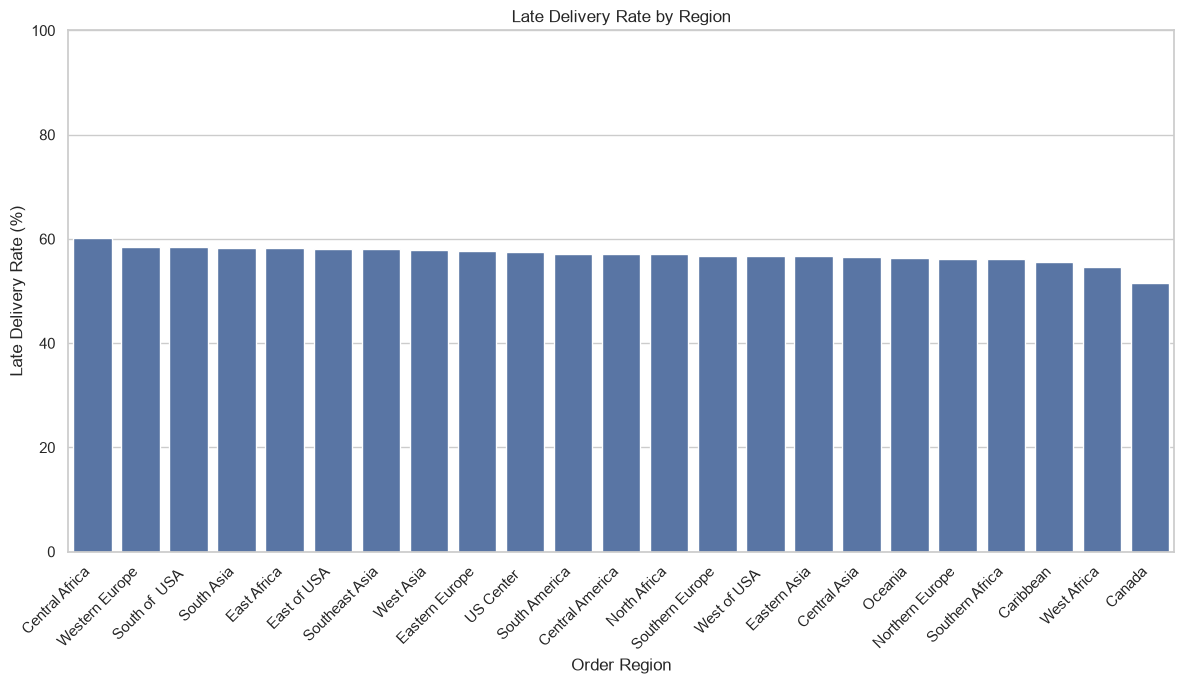

In [22]:
# Visualise regional late-delivery rates

plt.figure(figsize=(12, 7))

sns.barplot(
    data=regional_analysis.reset_index(),
    x="Order Region",
    y="late_delivery_rate"
)

plt.title("Late Delivery Rate by Region")

plt.xlabel("Order Region")

plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 100)

plt.tight_layout()

plt.show()

In [23]:
# Compare late-delivery volume across regions

regional_volume = regional_analysis.sort_values(
    by="late_records",
    ascending=False
)

display(regional_volume[
    ["total_records", "late_records", "late_delivery_rate"]
].round(2))

,total_records,late_records,late_delivery_rate
Order Region,,,
Central America,27174,15518,57.11
Western Europe,25867,15140,58.53
South America,14184,8111,57.18
Oceania,9733,5482,56.32
Southeast Asia,9136,5297,57.98
Northern Europe,9408,5292,56.25
Southern Europe,9030,5129,56.80
Caribbean,7951,4415,55.53
South Asia,7455,4350,58.35


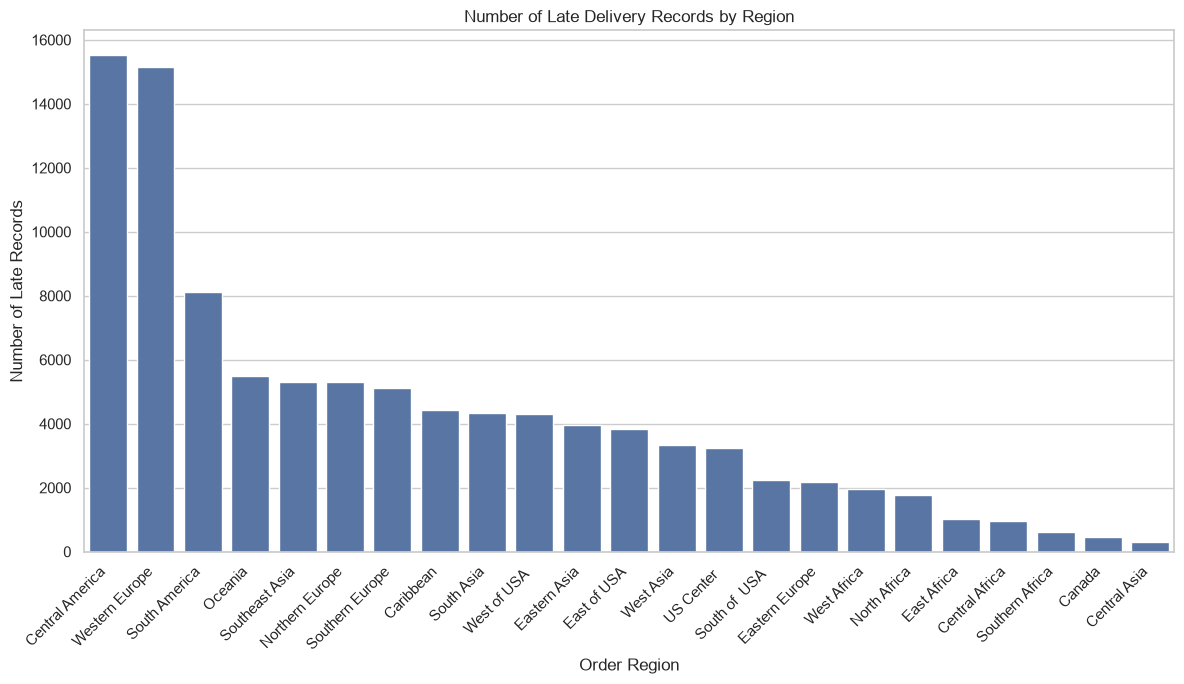

In [24]:
# visualise the number of late records:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=regional_volume.reset_index(),
    x="Order Region",
    y="late_records"
)

plt.title("Number of Late Delivery Records by Region")

plt.xlabel("Order Region")

plt.ylabel("Number of Late Records")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

## Regional Business Findings 

# Business Findings: Regional Delivery Analysis

1. The region with the highest late-delivery rate is CENTRAL AFRICA.

2. The region with the lowest late-delivery rate is CANADA.

3. The region with the highest number of late records is CENTRAL AMERICA.

4. The region with the lowest number of late records is CENTRAL ASIA.

5. The results indicate that delivery performance
   varies across geographical regions.

6. Regions with high late-delivery rates should be
   investigated further to identify possible
   operational challenges.

7. Further analysis is required to understand the
   influence of shipping modes, order volume and
   product categories on regional performance.

In [25]:
# Create a dataset containing only non-cancelled deliveries

analysis_df = df[
    df["Delivery Status"] != "Shipping canceled"
].copy()

print("Original records:", len(df))
print("Non-cancelled records:", len(analysis_df))
print("Cancelled records:", len(df) - len(analysis_df))

Original records: 180519
Non-cancelled records: 172765
Cancelled records: 7754


In [26]:
# products in each category 
category_counts = df["Category Name"].value_counts()

print(category_counts)

Category Name
Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Accessories              1780
Golf Balls               1475
Girls' Apparel           1201
Golf Gloves              1070
Trade-In                  974
Video Games               838
Children's Clothing       652
Women's Clothing          650
Baseball & Softball       632
Hockey                    614
Cameras                   592
Toys                      529
Golf Shoes                524
Pet Supplies              492
Crafts                    484
Garden                    484
DVDs                      483
Computers                 442
Golf Apparel              441
Hunting & Shooting        440
Music                     434
Consumer Electronics      431
Boxing & MMA              

In [27]:
# late delivery rate by product category 

category_analysis = analysis_df.groupby("Category Name").agg(
    total_records=("Late_delivery_risk", "count"),
    late_records=("Late_delivery_risk", "sum"),
    average_actual_days=("Days for shipping (real)", "mean"),
    average_scheduled_days=("Days for shipment (scheduled)", "mean")
)

category_analysis["late_delivery_rate"] = (
    category_analysis["late_records"] /
    category_analysis["total_records"]
) * 100

category_analysis = category_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

print(category_analysis.round(2))

                      total_records  late_records  average_actual_days  \
Category Name                                                            
Golf Bags & Carts                61            42                 3.34   
Lacrosse                        329           206                 3.60   
Pet Supplies                    472           290                 3.38   
Cameras                         562           344                 3.32   
Accessories                    1697          1014                 3.50   
Music                           417           248                 3.49   
Fitness Accessories             296           176                 3.58   
Boxing & MMA                    402           238                 3.48   
Crafts                          458           271                 3.58   
As Seen on  TV!                  66            39                 3.68   
Sporting Goods                  336           198                 3.48   
Strength Training               109   

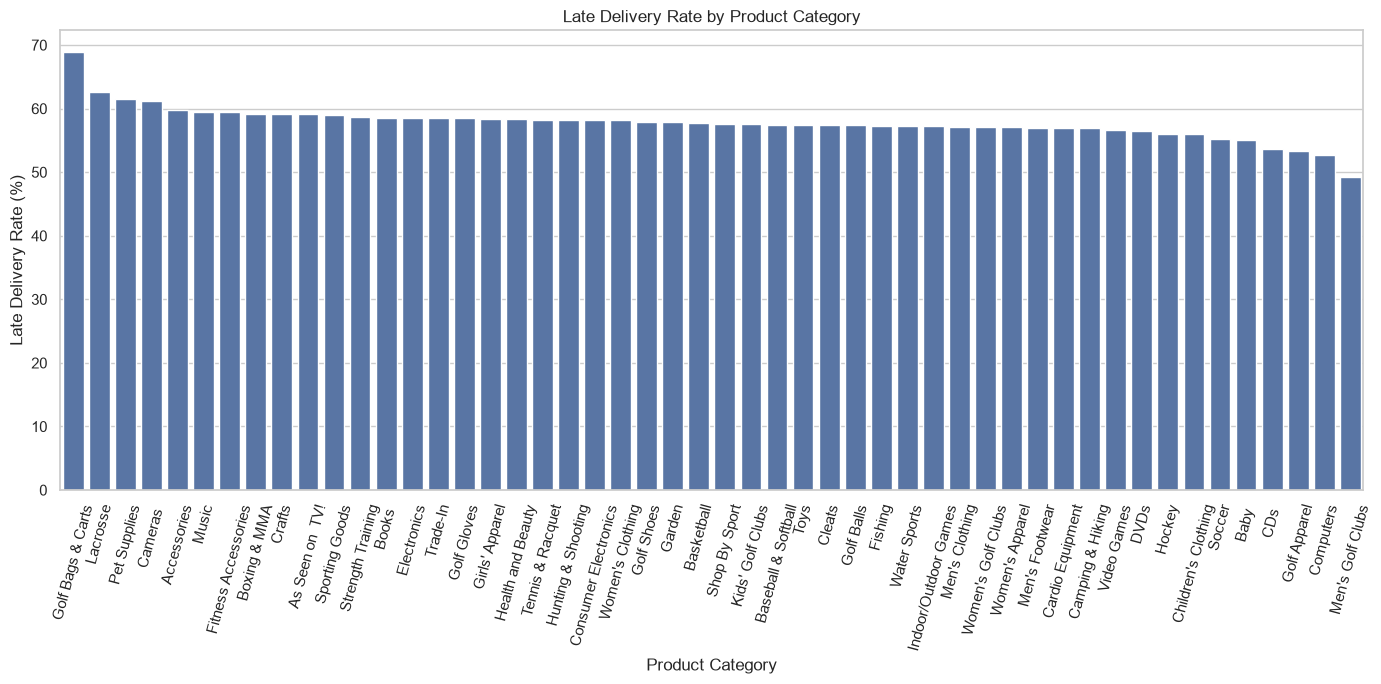

In [28]:
# visualization of late delivery records by product category

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["late_delivery_rate"]
)

plt.title("Late Delivery Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [29]:
# delivery performance by department 

department_analysis = analysis_df.groupby("Department Name").agg(
    total_records=("Late_delivery_risk", "count"),
    late_records=("Late_delivery_risk", "sum")
)

department_analysis["late_delivery_rate"] = (
    department_analysis["late_records"] /
    department_analysis["total_records"]
) * 100

department_analysis = department_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

print(department_analysis.round(2))

                    total_records  late_records  late_delivery_rate
Department Name                                                    
Pet Shop                      472           290               61.44
Book Shop                     391           229               58.57
Health and Beauty             346           202               58.38
Fitness                      2374          1377               58.00
Outdoors                     9267          5375               58.00
Technology                   1396           806               57.74
Golf                        31768         18198               57.28
Footwear                    13891          7949               57.22
Apparel                     46884         26825               57.22
Fan Shop                    64033         36623               57.19
Discs Shop                   1943          1103               56.77


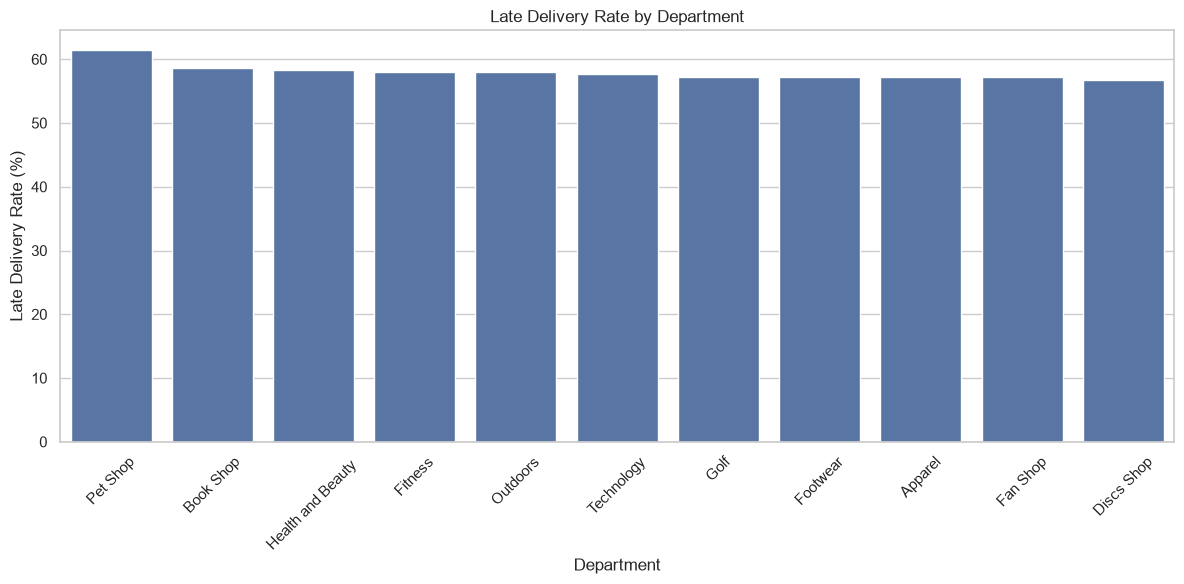

In [30]:
# visualization for delivery department wise
plt.figure(figsize=(12, 6))

sns.barplot(
    x=department_analysis.index,
    y=department_analysis["late_delivery_rate"]
)

plt.title("Late Delivery Rate by Department")
plt.xlabel("Department")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Business Findings: Product Category and Department Analysis

1. The product category with the highest late-delivery rate is Golf Bags & Carts.

2. The product category with the lowest late-delivery rate is Men's Golf Club.

3. The department with the highest late-delivery rate is Pet Shop.

4. The department with the lowest late-delivery rate is Discs Shop.

5. Delivery performance varies across product categories and departments.

6. Categories with high late-delivery rates should be investigated further to identify possible operational issues.

In [31]:
# Extracting Month and Year record 
analysis_df["order_month"] = (
    analysis_df["order date (DateOrders)"].dt.to_period("M")
)

print(analysis_df[
    ["order date (DateOrders)", "order_month"]
].head())

  order date (DateOrders) order_month
0     2018-01-31 22:56:00     2018-01
1     2018-01-13 12:27:00     2018-01
2     2018-01-13 12:06:00     2018-01
3     2018-01-13 11:45:00     2018-01
4     2018-01-13 11:24:00     2018-01


In [32]:
# Monthly order volume and late-delivery rate 

monthly_analysis = analysis_df.groupby("order_month").agg(
    total_records=("Late_delivery_risk", "count"),
    late_records=("Late_delivery_risk", "sum")
)

monthly_analysis["late_delivery_rate"] = (
    monthly_analysis["late_records"] /
    monthly_analysis["total_records"]
) * 100

print(monthly_analysis.round(2))

             total_records  late_records  late_delivery_rate
order_month                                                 
2015-01               5114          2880               56.32
2015-02               4487          2594               57.81
2015-03               5127          2936               57.27
2015-04               4915          2760               56.15
2015-05               5087          2951               58.01
2015-06               4908          2778               56.60
2015-07               5124          2939               57.36
2015-08               5025          2936               58.43
2015-09               4926          2914               59.16
2015-10               5073          2906               57.28
2015-11               5019          2841               56.60
2015-12               5149          2937               57.04
2016-01               5105          2955               57.88
2016-02               4683          2650               56.59
2016-03               50

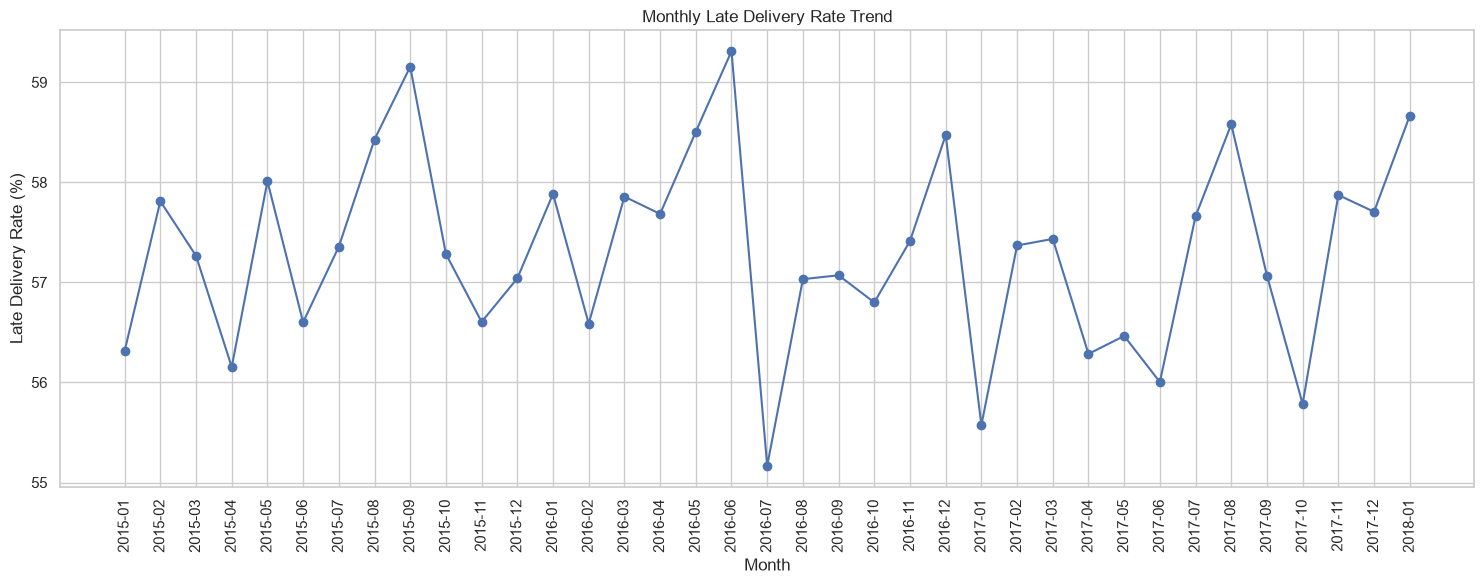

In [33]:
# Visualize monthly late-delivery rate

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["late_delivery_rate"],
    marker="o"
)

plt.title("Monthly Late Delivery Rate Trend")
plt.xlabel("Month")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
# Analyzing yearly data 

analysis_df["order_year"] = (
    analysis_df["order date (DateOrders)"].dt.year
)

yearly_analysis = analysis_df.groupby("order_year").agg(
    total_records=("Late_delivery_risk", "count"),
    late_records=("Late_delivery_risk", "sum")
)

yearly_analysis["late_delivery_rate"] = (
    yearly_analysis["late_records"] /
    yearly_analysis["total_records"]
) * 100

print(yearly_analysis.round(2))

            total_records  late_records  late_delivery_rate
order_year                                                 
2015                59954         34372               57.33
2016                59926         34446               57.48
2017                50848         28964               56.96
2018                 2037          1195               58.66


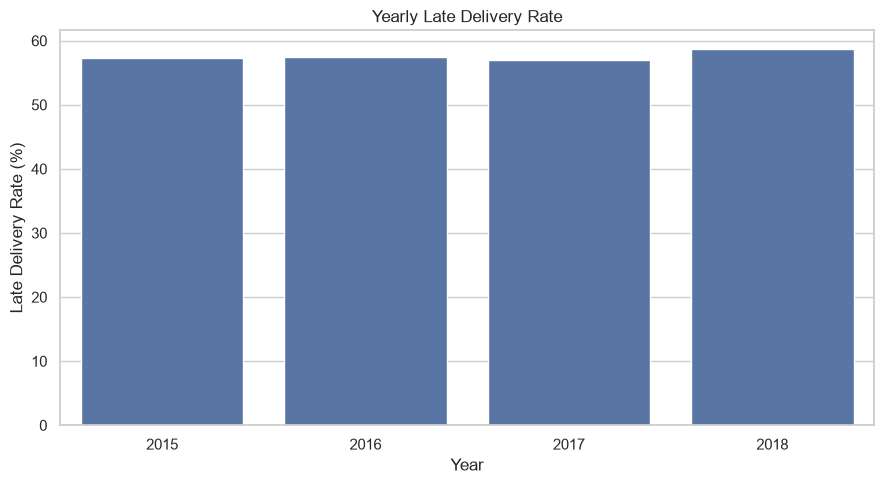

In [35]:
# Visualization data for it
plt.figure(figsize=(9, 5))

sns.barplot(
    x=yearly_analysis.index.astype(str),
    y=yearly_analysis["late_delivery_rate"]
)

plt.title("Yearly Late Delivery Rate")
plt.xlabel("Year")
plt.ylabel("Late Delivery Rate (%)")

plt.tight_layout()
plt.show()

## Business Findings: Time-Based Delivery Analysis

1. The month with the highest late-delivery rate is 2016-06.

2. The month with the lowest late-delivery rate is 2016-07.

3. The year with the highest late-delivery rate is 2018.

4. The year with the lowest late-delivery rate is 2017.

5. Monthly analysis indicates that delivery performance got poor over time.

6. Time-based analysis helps identify periods when delivery operations may require additional attention.

In [36]:
# Checking distribution of delay days 

delay_distribution = analysis_df[
    "shipping_delay_days"
].value_counts().sort_index()

print(delay_distribution)

shipping_delay_days
-2    20873
-1    20719
 0    32196
 1    57957
 2    27551
 3     6772
 4     6697
Name: count, dtype: int64


In [37]:
# classify on the basis of delivery delay 

def classify_delay(days):

    if days < 0:
        return "Early"

    elif days == 0:
        return "On Time"

    else:
        return "Late"


analysis_df["delay_category"] = (
    analysis_df["shipping_delay_days"].apply(classify_delay)
)

print(analysis_df["delay_category"].value_counts())

delay_category
Late       98977
Early      41592
On Time    32196
Name: count, dtype: int64


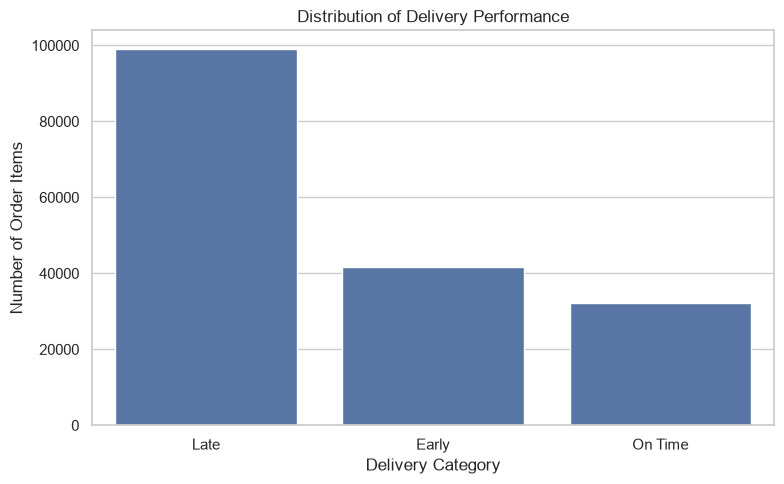

In [38]:
# Analyzing the late-delivery categories

delay_counts = analysis_df["delay_category"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=delay_counts.index,
    y=delay_counts.values
)

plt.title("Distribution of Delivery Performance")
plt.xlabel("Delivery Category")
plt.ylabel("Number of Order Items")

plt.tight_layout()
plt.show()

In [39]:
# Severity of late delivery 

late_only = analysis_df[
    analysis_df["shipping_delay_days"] > 0
].copy()

severity_analysis = late_only[
    "shipping_delay_days"
].value_counts().sort_index()

print(severity_analysis)

shipping_delay_days
1    57957
2    27551
3     6772
4     6697
Name: count, dtype: int64


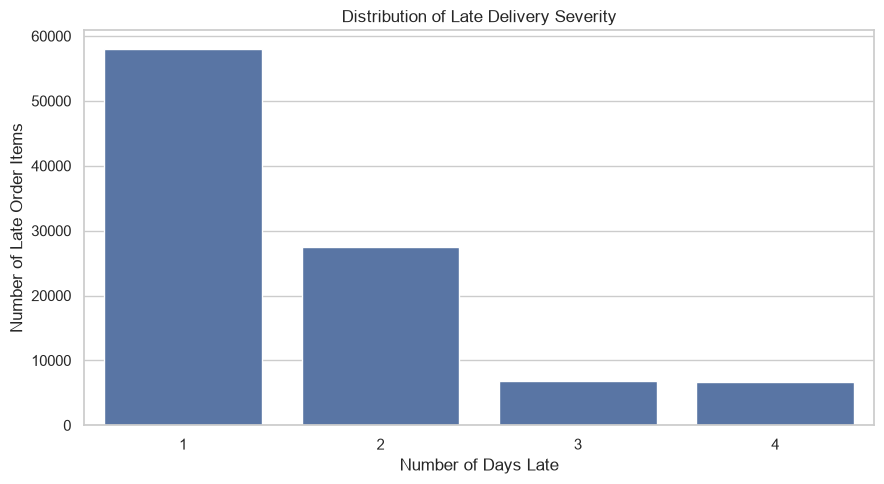

In [40]:
# visualization of late delivery 
plt.figure(figsize=(9, 5))

sns.barplot(
    x=severity_analysis.index,
    y=severity_analysis.values
)

plt.title("Distribution of Late Delivery Severity")
plt.xlabel("Number of Days Late")
plt.ylabel("Number of Late Order Items")

plt.tight_layout()
plt.show()

In [41]:
# Average delay over late deliveries 
average_delay = late_only["shipping_delay_days"].mean()

maximum_delay = late_only["shipping_delay_days"].max()

print("Average delay:", round(average_delay, 2), "days")
print("Maximum delay:", maximum_delay, "days")

Average delay: 1.62 days
Maximum delay: 4 days


## Business Findings: Delivery Delay Severity

1. The most common delivery performance category is Late Delivery.

2. The most common delay duration among late deliveries is 1-day delay duration.

3. The average delay among late deliveries is 1.62 days.

4. The maximum recorded delay is 4 days.

5. The analysis indicates that late deliveries are not equally severe.

6. The company should investigate not only the frequency of late deliveries but also how long customers experience delays.

In [42]:
# comparing financial metrics for late-delivery

financial_analysis = analysis_df.groupby("Delivery Status").agg(

    total_records=("Order Item Id", "count"),

    total_sales=("Sales", "sum"),

    average_sales=("Sales", "mean"),

    total_order_value=("Order Item Total", "sum"),

    average_order_value=("Order Item Total", "mean"),

    total_profit=("Order Profit Per Order", "sum"),

    average_profit=("Order Profit Per Order", "mean"),

    average_discount=("Order Item Discount", "mean")

)

print(financial_analysis.round(2))

                  total_records  total_sales  average_sales  \
Delivery Status                                               
Advance shipping          41592   8518007.89         204.80   
Late delivery             98977  20126395.27         203.34   
Shipping on time          32196   6570026.50         204.06   

                  total_order_value  average_order_value  total_profit  \
Delivery Status                                                          
Advance shipping         7656338.75               184.08     935225.28   
Late delivery           18082555.30               182.69    2140051.68   
Shipping on time         5905771.03               183.43     731143.67   

                  average_profit  average_discount  
Delivery Status                                     
Advance shipping           22.49             20.72  
Late delivery              21.62             20.65  
Shipping on time           22.71             20.63  


In [43]:
# calculating sales associated with late deliveries 

late_financial = analysis_df[
    analysis_df["Delivery Status"] == "Late delivery"
]

late_sales = late_financial["Sales"].sum()

total_sales = analysis_df["Sales"].sum()

late_sales_percentage = (
    late_sales / total_sales
) * 100

print("Sales associated with late deliveries:", round(late_sales, 2))

print("Total non-cancelled sales:", round(total_sales, 2))

print("Percentage of sales associated with late deliveries:",
      round(late_sales_percentage, 2), "%")

Sales associated with late deliveries: 20126395.27
Total non-cancelled sales: 35214429.65
Percentage of sales associated with late deliveries: 57.15 %


In [44]:
# profit across delivery status

profit_analysis = analysis_df.groupby("Delivery Status")[
    "Order Profit Per Order"
].sum().sort_values(ascending=False)

print(profit_analysis)

Delivery Status
Late delivery       2.140052e+06
Advance shipping    9.352253e+05
Shipping on time    7.311437e+05
Name: Order Profit Per Order, dtype: float64


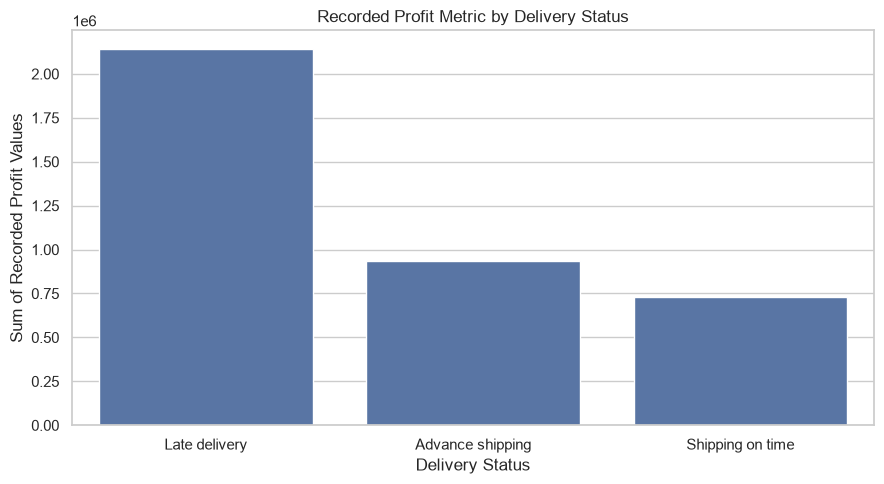

In [45]:
# visualization of it 
plt.figure(figsize=(9, 5))

sns.barplot(
    x=profit_analysis.index,
    y=profit_analysis.values
)

plt.title("Recorded Profit Metric by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Sum of Recorded Profit Values")

plt.tight_layout()
plt.show()

In [46]:
# analyzing negative profit records 

negative_profit = analysis_df[
    analysis_df["Order Profit Per Order"] < 0
]

negative_profit_by_status = negative_profit[
    "Delivery Status"
].value_counts()

print(negative_profit_by_status)

Delivery Status
Late delivery       18553
Advance shipping     7772
Shipping on time     5970
Name: count, dtype: int64


## Business Findings: Financial and Profitability Analysis

1. Total recorded sales associated with late deliveries are 20126395.27.

2. The percentage of non-cancelled sales associated with late deliveries is 57.15 %.

3. The delivery status with the highest total recorded profit metric is Late Delivery.

4. The delivery status with the lowest total recorded profit metric is Shipping on Time.

5. Negative-profit records are observed across Delivery status.

6. The results indicate that delivery performance and financial metrics can be investigated together.

7. Sales associated with delayed deliveries represent revenue exposure and should not automatically be treated as actual financial loss.

In [47]:
# Analyse region and shipping mode together

region_shipping_analysis = analysis_df.groupby(
    ["Order Region", "Shipping Mode"]
).agg(

    total_records=("Late_delivery_risk", "count"),

    late_records=("Late_delivery_risk", "sum")

)

region_shipping_analysis["late_delivery_rate"] = (
    region_shipping_analysis["late_records"] /
    region_shipping_analysis["total_records"]
) * 100

region_shipping_analysis = region_shipping_analysis.sort_values(
    by="late_delivery_rate",
    ascending=False
)

print(region_shipping_analysis.round(2))

                                total_records  late_records  \
Order Region    Shipping Mode                                 
Canada          First Class               170           170   
Caribbean       First Class              1132          1132   
Central Africa  First Class               278           278   
Central America First Class              4185          4185   
East Africa     First Class               277           277   
...                                       ...           ...   
Eastern Europe  Same Day                  176            64   
Central Africa  Same Day                   79            24   
Canada          Standard Class            554           166   
                Same Day                   29             7   
Central Asia    Same Day                   64            13   

                                late_delivery_rate  
Order Region    Shipping Mode                       
Canada          First Class                 100.00  
Caribbean       First

In [50]:
# Finding the worst-performing combinations
print("Top 10 combinations with highest late-delivery rates:")



reliable_combinations = region_shipping_analysis[
    region_shipping_analysis["total_records"] >= 100
]

print(reliable_combinations.head(10).round(2))

Top 10 combinations with highest late-delivery rates:
                               total_records  late_records  late_delivery_rate
Order Region    Shipping Mode                                                 
Canada          First Class              170           170               100.0
Caribbean       First Class             1132          1132               100.0
Central Africa  First Class              278           278               100.0
Central America First Class             4185          4185               100.0
East Africa     First Class              277           277               100.0
East of USA     First Class             1050          1050               100.0
South Asia      First Class             1240          1240               100.0
North Africa    First Class              472           472               100.0
Northern Europe First Class             1361          1361               100.0
Eastern Europe  First Class              632           632               100.

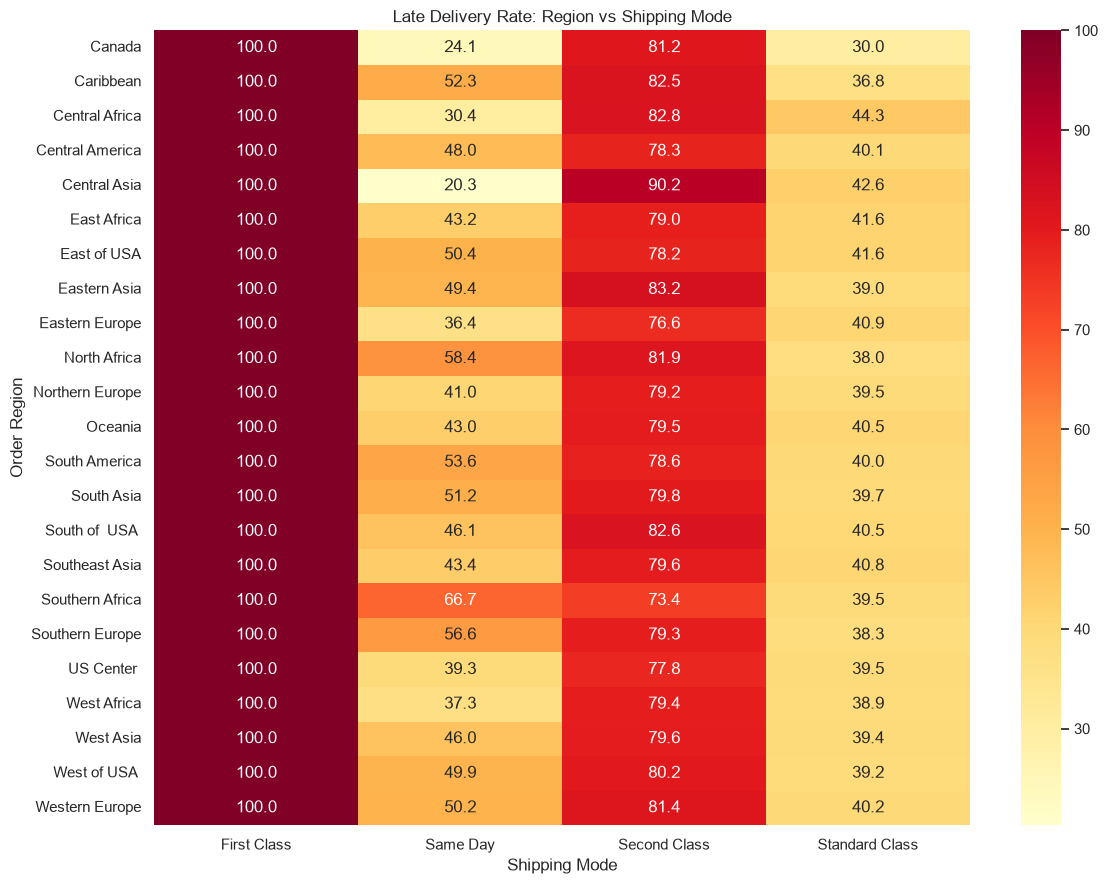

In [51]:
# creating a heat map
heatmap_data = analysis_df.pivot_table(

    index="Order Region",

    columns="Shipping Mode",

    values="Late_delivery_risk",

    aggfunc="mean"

) * 100

plt.figure(figsize=(12, 9))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Late Delivery Rate: Region vs Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Order Region")

plt.tight_layout()
plt.show()

In [52]:
# analyze product category and shipping mode together

category_shipping = analysis_df.groupby(
    ["Category Name", "Shipping Mode"]
).agg(

    total_records=("Late_delivery_risk", "count"),

    late_records=("Late_delivery_risk", "sum")

)

category_shipping["late_delivery_rate"] = (
    category_shipping["late_records"] /
    category_shipping["total_records"]
) * 100

category_shipping = category_shipping.sort_values(
    by="late_delivery_rate",
    ascending=False
)

print(category_shipping.head(15).round(2))

                                    total_records  late_records  \
Category Name        Shipping Mode                                
Accessories          First Class              278           278   
As Seen on  TV!      First Class                9             9   
Books                First Class               53            53   
Basketball           First Class               13            13   
                     Second Class              10            10   
Baseball & Softball  First Class              103           103   
Baby                 First Class               33            33   
Consumer Electronics First Class               58            58   
Crafts               First Class               79            79   
Electronics          First Class              470           470   
DVDs                 First Class               58            58   
Cleats               First Class             3583          3583   
Camping & Hiking     First Class             1960          196

# FINAL BUSINESS FINDINGS – SUPPLY CHAIN ANALYSIS

## 1. Overall Delivery Performance

- Late deliveries account for 57.29% of non-cancelled records.
- The company has a substantial delivery-performance issue.

## 2. Shipping Mode Analysis

- First Class has the highest late-delivery rate.
- Standard Class has the lowest late-delivery rate.
- Delivery performance differs across shipping modes.

## 3. Regional Analysis

- Central Africa has the highest late-delivery rate.
- Canada has the lowest late-delivery rate.
- Central America has the highest number of late records.

## 4. Product Category Analysis

- Highest late-delivery category: Golf Bags & Carts.
- Lowest late-delivery category: Men's Golf Club.
- Further investigation is needed to identify product-related patterns.

## 5. Time-Based Analysis

- Highest late-delivery month: 2016-06.
- Lowest late-delivery month: 2016-07.
- Yearly trend: 2018 Highest Late-Delivery meanwhile 2017 Lowest-Delivery Year.

## 6. Delay Severity Analysis

- Most common delay duration: 1 day.
- Average delay: 1.62 days.
- Maximum delay: 4 days.

## 7. Financial Analysis

- Sales associated with late deliveries: 20126395.27.
- Percentage of sales associated with late deliveries: 57.15%.
- Financial metrics should be investigated alongside delivery performance.

## 8. Combined Analysis

- Worst-performing region and shipping mode combination: Canada.
- Product category and shipping mode observations: 100% late delivery rate.

## 9. Overall Conclusion

The analysis indicates that delivery performance varies across shipping
modes, geographical regions, product categories and time periods.

Further investigation of these factors can help the company identify
operational areas that require attention and improve supply chain
delivery performance.   

In [53]:
# SAVING THE EDA ANALYSIS REPORT 
# Create a folder for EDA outputs

import os

os.makedirs("../reports/eda", exist_ok=True)

# Export important analysis tables

category_analysis.to_csv(
    "../reports/eda/category_analysis.csv"
)

department_analysis.to_csv(
    "../reports/eda/department_analysis.csv"
)

monthly_analysis.to_csv(
    "../reports/eda/monthly_analysis.csv"
)

yearly_analysis.to_csv(
    "../reports/eda/yearly_analysis.csv"
)

severity_analysis.to_csv(
    "../reports/eda/delay_severity.csv"
)

financial_analysis.to_csv(
    "../reports/eda/financial_analysis.csv"
)

region_shipping_analysis.to_csv(
    "../reports/eda/region_shipping_analysis.csv"
)

category_shipping.to_csv(
    "../reports/eda/category_shipping_analysis.csv"
)

print("All EDA analysis tables exported successfully!")

All EDA analysis tables exported successfully!
